# Pemrosesan Awal & Eksplorasi Data — Tanaman Biofarmaka Kabupaten Kediri

Notebook ini memproses dan mengeksplorasi 4 file data BPS:

| Variabel | File | Level |
|---|---|---|
| `luas_kab` | `luas_panen_biofarmaka_kabupaten.csv` | Kabupaten |
| `luas_kec` | `luas_panen_biofarmaka_per_kecamatan.csv` | Kecamatan |
| `prod_kab` | `produksi_biofarmaka_kabupaten.csv` | Kabupaten |
| `prod_kec` | `produksi_biofarmaka_per_kecamatan.csv` | Kecamatan |

**Alur:** (1) Muat data → (2) Cek kualitas → (3) Pembersihan & penggabungan → (4) EDA → (5) Kesimpulan → (6) Simpan data bersih.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import os

pd.set_option("display.float_format", lambda x: f"{x:,.2f}")
pd.set_option("display.max_columns", None)
pd.set_option("display.width", 200)
sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams["figure.dpi"] = 110


def cari_project_root(start_path=None):
    # Naik folder satu per satu sampai ketemu root project
    # (punya folder data/ DAN notebooks/ atau .git).
    start = os.path.abspath(start_path or os.getcwd())
    current = start

    while True:
        if (
            os.path.isdir(os.path.join(current, "data"))
            and (
                os.path.isdir(os.path.join(current, "notebooks"))
                or os.path.isdir(os.path.join(current, ".git"))
            )
        ):
            return current

        parent = os.path.dirname(current)
        if parent == current:
            break
        current = parent

    # cadangan: anggap notebook ada 1 level di dalam root project
    return os.path.abspath(os.path.join(start, ".."))


def cari_file(nama_file, folder_utama):
    # Cari file di folder_utama dulu. Kalau tidak ada, cari ke seluruh folder data/.
    langsung = os.path.join(folder_utama, nama_file)
    if os.path.isfile(langsung):
        return langsung
    for root, _, files in os.walk(DATA_DIR):
        if nama_file in files:
            return os.path.join(root, nama_file)
    raise FileNotFoundError(f"'{nama_file}' tidak ditemukan di {folder_utama} maupun di dalam {DATA_DIR}")


def baca_csv(path):
    # utf-8-sig: buang karakter BOM tak terlihat yang ditambahkan Excel di awal file
    df = pd.read_csv(path, encoding="utf-8-sig")
    # rapikan nama kolom: buang spasi & jadikan huruf kecil
    df.columns = df.columns.str.strip().str.lower()
    # kalau kolom wilayah bernama 'kabupaten', samakan jadi 'kecamatan' (nanti di-rename lagi di bagian cleaning)
    if "kecamatan" not in df.columns and "kabupaten" in df.columns:
        df = df.rename(columns={"kabupaten": "kecamatan"})
    return df


PROJECT_ROOT = cari_project_root()
DATA_DIR = os.path.join(PROJECT_ROOT, "data")

RAW_BIOFARMAKA = os.path.join(DATA_DIR, "raw", "biofarmaka")
OUT_BIOFARMAKA = os.path.join(DATA_DIR, "clean", "biofarmaka")   # hasil cleaning
os.makedirs(OUT_BIOFARMAKA, exist_ok=True)

print("PROJECT ROOT :", PROJECT_ROOT)
print("RAW BIO      :", RAW_BIOFARMAKA)
print("CLEAN OUTPUT :", OUT_BIOFARMAKA)

PROJECT ROOT : c:\Users\Zerlina\Documents\PENS\SEMESTER 5\project analitika data\AgriDash-0.1
RAW BIO      : c:\Users\Zerlina\Documents\PENS\SEMESTER 5\project analitika data\AgriDash-0.1\data\raw\biofarmaka
CLEAN OUTPUT : c:\Users\Zerlina\Documents\PENS\SEMESTER 5\project analitika data\AgriDash-0.1\data\clean\biofarmaka


## 1. Muat Data

In [2]:
FILES = {
    "luas_kab" : "luas_panen_biofarmaka_kabupaten.csv",
    "luas_kec" : "luas_panen_biofarmaka_per_kecamatan.csv",
    "prod_kab" : "produksi_biofarmaka_kabupaten.csv",
    "prod_kec" : "produksi_biofarmaka_per_kecamatan.csv",
}
PATHS = {k: cari_file(v, RAW_BIOFARMAKA) for k, v in FILES.items()}
raw = {k: baca_csv(p) for k, p in PATHS.items()}

for k, p in PATHS.items():
    print(f"{k:9s} <- {p}")
print()

for k, df in raw.items():
    print(f"{k:9s} -> {df.shape[0]:>4} baris x {df.shape[1]} kolom | kolom: {list(df.columns)}")

# --- KONVERTER: ubah file kecamatan format LEBAR (kolom per komoditas) jadi format PANJANG ---
import re

def kolom_nilai(df):
    # nama kolom nilai: luas_panen (file luas) atau produksi_kg (file produksi)
    return "luas_panen" if "luas_panen" in df.columns else "produksi_kg"

def norm(s):
    return re.sub(r"[^a-z0-9]", "", str(s).lower())

# daftar komoditas resmi diambil dari file kabupaten (formatnya sudah panjang)
resmi = {norm(x): x for x in raw["luas_kab"]["komoditas"].dropna().unique()}
BARIS_TOTAL = {"kediri", "kabupatenkediri", "jumlah", "total", "kabupaten"}

def lebar_ke_panjang(df, nama_nilai):
    if "komoditas" in df.columns and nama_nilai in df.columns:      # sudah panjang -> biarkan
        return df
    kol_kom = {c: resmi[norm(c)] for c in df.columns if norm(c) in resmi}
    if "kecamatan" not in df.columns or not kol_kom:
        raise ValueError(f"Format file ({nama_nilai}) tidak dikenali. Kolom yang ada: {df.columns.tolist()}")
    p = df.melt(id_vars="kecamatan", value_vars=list(kol_kom), var_name="komoditas", value_name="_mentah")
    p["komoditas"] = p["komoditas"].map(kol_kom)

    angka = pd.to_numeric(p["_mentah"], errors="coerce")             # "-" dan teks lain -> NaN
    ada_isi = p["_mentah"].notna() & ~p["_mentah"].astype(str).str.strip().isin(["-", "", "nan"])
    gagal = p.loc[ada_isi & angka.isna(), "_mentah"]
    if len(gagal):
        print(f"PERINGATAN {nama_nilai}: {len(gagal)} nilai tidak bisa dibaca sebagai angka, contoh: {gagal.unique()[:5].tolist()}")
    p[nama_nilai] = angka

    total = p["kecamatan"].map(norm).isin(BARIS_TOTAL)
    if total.any():
        print(f"{nama_nilai}: {total.sum()} baris total dibuang ({p.loc[total, 'kecamatan'].unique().tolist()})")
    return p.loc[~total].drop(columns="_mentah").reset_index(drop=True)

raw["luas_kec"] = lebar_ke_panjang(raw["luas_kec"], "luas_panen")
raw["prod_kec"] = lebar_ke_panjang(raw["prod_kec"], "produksi_kg")

# satuan luas untuk file kecamatan: ambil dari file kabupaten kalau ada
if "satuan_luas_panen" in raw["luas_kab"].columns and "satuan_luas_panen" not in raw["luas_kec"].columns:
    peta_satuan = raw["luas_kab"].drop_duplicates("komoditas").set_index("komoditas")["satuan_luas_panen"]
    raw["luas_kec"]["satuan_luas_panen"] = raw["luas_kec"]["komoditas"].map(peta_satuan)

# pemeriksaan akhir: kalau masih ada kolom yang kurang, tampilkan kolom aslinya di pesan error
WAJIB = {"luas_kab": ["kecamatan", "komoditas", "luas_panen"], "luas_kec": ["kecamatan", "komoditas", "luas_panen"],
         "prod_kab": ["kecamatan", "komoditas", "produksi_kg"], "prod_kec": ["kecamatan", "komoditas", "produksi_kg"]}
masalah = [f"{k}: tidak ada {[c for c in w if c not in raw[k].columns]} | kolom: {raw[k].columns.tolist()}"
           for k, w in WAJIB.items() if any(c not in raw[k].columns for c in w)]
if masalah:
    raise ValueError("Kolom tidak sesuai:\n  " + "\n  ".join(masalah))
for k, df in raw.items():
    print(f"{k:9s} baris={len(df):>4} kolom={df.columns.tolist()}")

# --- PENYESUAI: lengkapi kolom QC kalau file tidak punya ---
for k, df in raw.items():
    nilai = kolom_nilai(df)
    if "is_estimate" not in df.columns:
        df["is_estimate"] = False
    if "metode" not in df.columns:
        df["metode"] = "tidak tercatat"
    if "status_qc" not in df.columns:          # OK kalau ada nilainya, kosong kalau tidak
        df["status_qc"] = np.where(df[nilai].notna(), "OK", None)

# satuan luas: kalau masih belum ada, tentukan dari jenis komoditas (pohon vs m2)
KOMODITAS_POHON = ["Jeruk Nipis", "Mahkota Dewa", "Mengkudu/Pace", "Serai"]
for k, df in raw.items():
    if "luas_panen" in df.columns and "satuan_luas_panen" not in df.columns:
        df["satuan_luas_panen"] = np.where(df["komoditas"].isin(KOMODITAS_POHON), "Pohon", "m2")
        print(f"{k}: kolom satuan_luas_panen tidak ada di file -> diisi dari daftar komoditas pohon")

luas_kab  <- c:\Users\Zerlina\Documents\PENS\SEMESTER 5\project analitika data\AgriDash-0.1\data\clean\biofarmaka\luas_panen_biofarmaka_kabupaten.csv
luas_kec  <- c:\Users\Zerlina\Documents\PENS\SEMESTER 5\project analitika data\AgriDash-0.1\data\raw\biofarmaka\luas_panen_biofarmaka_per_kecamatan.csv
prod_kab  <- c:\Users\Zerlina\Documents\PENS\SEMESTER 5\project analitika data\AgriDash-0.1\data\clean\biofarmaka\produksi_biofarmaka_kabupaten.csv
prod_kec  <- c:\Users\Zerlina\Documents\PENS\SEMESTER 5\project analitika data\AgriDash-0.1\data\raw\biofarmaka\produksi_biofarmaka_per_kecamatan.csv

luas_kab  ->   16 baris x 7 kolom | kolom: ['kecamatan', 'komoditas', 'luas_panen', 'satuan_luas_panen', 'is_estimate', 'metode', 'status_qc']
luas_kec  ->   27 baris x 17 kolom | kolom: ['kecamatan', 'luas panen jahe (meter persegi) (m2)', 'luas panen kapulaga (meter persegi) (m2)', 'luas panen keji beling (meter persegi) (m2)', 'luas panen kencur (meter persegi) (m2)', 'luas panen kunyit (meter

ValueError: Format file (luas_panen) tidak dikenali. Kolom yang ada: ['kecamatan', 'luas panen jahe (meter persegi) (m2)', 'luas panen kapulaga (meter persegi) (m2)', 'luas panen keji beling (meter persegi) (m2)', 'luas panen kencur (meter persegi) (m2)', 'luas panen kunyit (meter persegi) (m2)', 'luas panen laos/lengkuas (meter persegi) (m2)', 'luas panen lempuyang (meter persegi) (m2)', 'luas panen lidah buaya (meter persegi) (m2)', 'luas panen mahkota dewa (pohon) (pohon)', 'luas panen mengkudu/pace (pohon) (pohon)', 'luas panen sambiloto (meter persegi) (m2)', 'luas panen temuireng (meter persegi) (m2)', 'luas panen temukunci (meter persegi) (m2)', 'luas panen temulawak (meter persegi) (m2)', 'luas panen jeruk nipis (pohon) (pohon)', 'luas panen serai (meter persegi) (pohon)']

### 1.1 Catatan: penyesuaian format data

Supaya notebook tahan terhadap perbedaan format file, sel pemuatan data di atas otomatis:
- mengubah file **kecamatan** dari format *lebar* (satu kolom per komoditas) menjadi *panjang* (satu kolom `komoditas`), bila perlu;
- membuang baris total (mis. "Kediri", "Jumlah") dan mengubah tanda `-` menjadi kosong;
- melengkapi kolom QC (`is_estimate`, `metode`, `status_qc`) dan `satuan_luas_panen` bila belum ada;
- berhenti dengan pesan jelas (menampilkan kolom asli) kalau formatnya tidak dikenali.

Kalau file sudah berformat panjang dan lengkap, tidak ada yang diubah. Semua langkah ini ada dalam **satu sel**, jadi aman kalau sel pemuatan dijalankan ulang.

In [ ]:
for k, df in raw.items():
    print(f"\n=== {k} ===")
    display(df.head(5))


=== luas_kab ===


,kecamatan,komoditas,luas_panen,satuan_luas_panen,is_estimate,metode,status_qc
0,Kediri,Jahe,"92,260.00",m2,False,Data sumber BPS tingkat kecamatan,OK
1,Kediri,Kapulaga,"5,505.00",m2,False,Data sumber BPS tingkat kecamatan,OK
2,Kediri,Keji Beling,NaN,m2,False,Data sumber BPS tingkat kecamatan,NaN
3,Kediri,Kencur,"1,027.00",m2,False,Data sumber BPS tingkat kecamatan,OK
4,Kediri,Kunyit,"4,476,188.00",m2,False,Data sumber BPS tingkat kecamatan,OK



=== luas_kec ===


,kecamatan,komoditas,luas_panen,satuan_luas_panen,is_estimate,metode,status_qc
0,Mojo,Jahe,"5,000.00",m2,False,Data sumber BPS tingkat kecamatan,OK
1,Mojo,Kapulaga,"5,500.00",m2,False,Data sumber BPS tingkat kecamatan,OK
2,Mojo,Keji Beling,NaN,m2,False,Data sumber BPS tingkat kecamatan,NaN
3,Mojo,Kencur,NaN,m2,False,Data sumber BPS tingkat kecamatan,NaN
4,Mojo,Kunyit,"1,000.00",m2,False,Data sumber BPS tingkat kecamatan,OK



=== prod_kab ===


,kecamatan,komoditas,produksi_kg,is_estimate,metode,status_qc
0,Kediri,Jahe,"133,603.00",False,Data sumber BPS tingkat kecamatan,OK
1,Kediri,Kapulaga,"21,263.00",False,Data sumber BPS tingkat kecamatan,OK
2,Kediri,Keji Beling,NaN,False,Data sumber BPS tingkat kecamatan,NaN
3,Kediri,Kencur,"6,910.00",False,Data sumber BPS tingkat kecamatan,OK
4,Kediri,Kunyit,"6,045,767.00",False,Data sumber BPS tingkat kecamatan,OK



=== prod_kec ===


,kecamatan,komoditas,produksi_kg,is_estimate,metode,status_qc
0,Mojo,Jahe,"9,200.00",False,Data sumber BPS tingkat kecamatan,OK
1,Mojo,Kapulaga,"21,250.00",False,Data sumber BPS tingkat kecamatan,OK
2,Mojo,Keji Beling,NaN,False,Data sumber BPS tingkat kecamatan,NaN
3,Mojo,Kencur,NaN,False,Data sumber BPS tingkat kecamatan,NaN
4,Mojo,Kunyit,"8,000.00",False,Data sumber BPS tingkat kecamatan,OK


## 2. Cek Kualitas Data (data mentah)

Yang dicek: missing value, duplikat, kolom yang isinya tidak bervariasi, dan konsistensi antar file.

In [ ]:
ringkasan = pd.DataFrame({
    k: {
        "baris": len(df),
        "jumlah_wilayah": df["kecamatan"].nunique(),
        "jumlah_komoditas": df["komoditas"].nunique(),
        "duplikat (wilayah+komoditas)": df.duplicated(["kecamatan", "komoditas"]).sum(),
        "nilai_kosong (kolom nilai)": df[kolom_nilai(df)].isna().sum(),
        "% kosong": round(df[kolom_nilai(df)].isna().mean() * 100, 1),
    } for k, df in raw.items()
}).T
ringkasan = ringkasan.astype({"baris": int, "jumlah_wilayah": int, "jumlah_komoditas": int,
                              "duplikat (wilayah+komoditas)": int, "nilai_kosong (kolom nilai)": int})
ringkasan

,baris,jumlah_wilayah,jumlah_komoditas,duplikat (wilayah+komoditas),nilai_kosong (kolom nilai),% kosong
luas_kab,16,1,16,0,5,31.20
luas_kec,416,26,16,0,366,88.00
prod_kab,16,1,16,0,5,31.20
prod_kec,416,26,16,0,366,88.00


In [ ]:
# Kolom yang isinya sama semua (tidak informatif)?
for k, df in raw.items():
    print(f"{k:9s} is_estimate={df['is_estimate'].unique().tolist()} | metode={df['metode'].unique().tolist()}")

print("\nIsi kolom 'kecamatan' di file level kabupaten:", raw["luas_kab"]["kecamatan"].unique().tolist())

luas_kab  is_estimate=[False] | metode=['Data sumber BPS tingkat kecamatan']
luas_kec  is_estimate=[False] | metode=['Data sumber BPS tingkat kecamatan']
prod_kab  is_estimate=[False] | metode=['Data sumber BPS tingkat kecamatan']
prod_kec  is_estimate=[False] | metode=['Data sumber BPS tingkat kecamatan']

Isi kolom 'kecamatan' di file level kabupaten: ['Kediri']


In [ ]:
# Apakah status_qc kosong persis di baris yang nilainya kosong?
for k in ["luas_kec", "prod_kec"]:
    df = raw[k]
    nilai = kolom_nilai(df)
    print(f"\n{k}")
    display(pd.crosstab(df[nilai].isna().rename("nilai_kosong"), df["status_qc"].fillna("(kosong)")))


luas_kec


status_qc,(kosong),OK
nilai_kosong,,
False,0,50
True,366,0



prod_kec


status_qc,(kosong),OK
nilai_kosong,,
False,0,50
True,366,0


In [ ]:
# Satuan luas panen per komoditas
raw["luas_kec"].groupby("satuan_luas_panen")["komoditas"].unique().apply(sorted)

satuan_luas_panen
Pohon    [Jeruk Nipis, Mahkota Dewa, Mengkudu/Pace, Serai]
m2       [Jahe, Kapulaga, Keji Beling, Kencur, Kunyit, ...
Name: komoditas, dtype: object

**Temuan dari pengecekan awal:**
- Tidak ada baris duplikat dan tidak ada nilai nol/negatif.
- File "kabupaten" cuma berisi 1 wilayah (**Kediri**) walau kolomnya bernama `kecamatan` → perlu di-rename jadi `kabupaten`.
- `is_estimate` (semua `False`) dan `metode` (satu nilai) tidak bervariasi → tidak berguna untuk analisis.
- `status_qc` kosong **persis** di baris yang nilainya kosong. Jadi kosong = "tidak ada data tercatat", bukan error.
- **Satuan luas campuran:** sebagian komoditas diukur dalam **m²**, sebagian dalam **pohon**. Dua satuan ini tidak boleh dijumlahkan atau dibandingkan langsung.

## 3. Pembersihan & Penggabungan

Langkah:
1. Rapikan teks (spasi) dan rename kolom wilayah di file kabupaten.
2. Isi `status_qc` kosong dengan label **"Tidak ada data"** (nilai angkanya **tetap NaN**, tidak diisi 0 atau diimputasi).
3. Buang kolom konstan (`is_estimate`, `metode`).
4. Gabungkan luas + produksi jadi satu tabel per level.
5. Hitung produktivitas sesuai satuan (kg/ha untuk m², kg/pohon untuk pohon).

In [ ]:
def bersihkan(df, level):
    df = df.copy()
    for c in ["kecamatan", "komoditas", "satuan_luas_panen", "status_qc"]:
        if c in df.columns:
            df[c] = df[c].astype("string").str.strip()

    if level == "kab":
        df = df.rename(columns={"kecamatan": "kabupaten"})

    df["status_qc"] = df["status_qc"].fillna("Tidak ada data")
    df["ada_data"] = df["status_qc"].eq("OK")

    # pastikan kolom yang dibuang memang konstan
    assert df["is_estimate"].nunique() == 1 and df["metode"].nunique() == 1
    return df.drop(columns=["is_estimate", "metode"])

luas_kab = bersihkan(raw["luas_kab"], "kab")
luas_kec = bersihkan(raw["luas_kec"], "kec")
prod_kab = bersihkan(raw["prod_kab"], "kab")
prod_kec = bersihkan(raw["prod_kec"], "kec")

luas_kec.head()

,kecamatan,komoditas,luas_panen,satuan_luas_panen,status_qc,ada_data
0,Mojo,Jahe,"5,000.00",m2,OK,True
1,Mojo,Kapulaga,"5,500.00",m2,OK,True
2,Mojo,Keji Beling,NaN,m2,Tidak ada data,False
3,Mojo,Kencur,NaN,m2,Tidak ada data,False
4,Mojo,Kunyit,"1,000.00",m2,OK,True


In [ ]:
def gabung(luas, prod, kunci):
    # kolom status_qc & ada_data dari tabel luas dan produksi harus sama -> cek dulu
    m = luas.merge(prod, on=kunci, how="outer", suffixes=("", "_prod"), validate="1:1", indicator=True)
    assert (m["_merge"] == "both").all(), "Ada baris yang tidak ada pasangannya!"
    assert (m["ada_data"] == m["ada_data_prod"]).all(), "Ketersediaan data luas vs produksi tidak sama!"

    m = m.drop(columns=["_merge", "status_qc_prod", "ada_data_prod"])
    m = m.rename(columns={"satuan_luas_panen": "satuan"})

    # luas dalam hektar (hanya untuk komoditas berukuran m2)
    m["luas_ha"] = np.where(m["satuan"].eq("m2"), m["luas_panen"] / 10_000, np.nan)

    # produktivitas: kg/ha untuk m2, kg/pohon untuk pohon
    m["produktivitas"] = np.where(
        m["satuan"].eq("m2"),
        m["produksi_kg"] / m["luas_panen"] * 10_000,
        m["produksi_kg"] / m["luas_panen"],
    )
    m["satuan_produktivitas"] = np.where(m["satuan"].eq("m2"), "kg/ha", "kg/pohon")
    return m

kec = gabung(luas_kec, prod_kec, ["kecamatan", "komoditas"])
kab = gabung(luas_kab, prod_kab, ["kabupaten", "komoditas"])

print("kec:", kec.shape, "| kab:", kab.shape)
kec.head(8)

kec: (416, 10) | kab: (16, 10)


,kecamatan,komoditas,luas_panen,satuan,status_qc,ada_data,produksi_kg,luas_ha,produktivitas,satuan_produktivitas
0,Badas,Jahe,NaN,m2,Tidak ada data,False,NaN,NaN,NaN,kg/ha
1,Badas,Jeruk Nipis,NaN,Pohon,Tidak ada data,False,NaN,NaN,NaN,kg/pohon
2,Badas,Kapulaga,NaN,m2,Tidak ada data,False,NaN,NaN,NaN,kg/ha
3,Badas,Keji Beling,NaN,m2,Tidak ada data,False,NaN,NaN,NaN,kg/ha
4,Badas,Kencur,NaN,m2,Tidak ada data,False,NaN,NaN,NaN,kg/ha
5,Badas,Kunyit,NaN,m2,Tidak ada data,False,NaN,NaN,NaN,kg/ha
6,Badas,Laos/Lengkuas,NaN,m2,Tidak ada data,False,NaN,NaN,NaN,kg/ha
7,Badas,Lempuyang,NaN,m2,Tidak ada data,False,NaN,NaN,NaN,kg/ha


### 3.1 Validasi: total semua kecamatan harus sama dengan angka kabupaten

In [ ]:
total_kec = kec.groupby("komoditas")[["luas_panen", "produksi_kg"]].sum(min_count=1)
cek = total_kec.join(kab.set_index("komoditas")[["luas_panen", "produksi_kg"]], rsuffix="_kab")
cek["selisih_luas"] = cek["luas_panen"] - cek["luas_panen_kab"]
cek["selisih_produksi"] = cek["produksi_kg"] - cek["produksi_kg_kab"]

display(cek.dropna(how="all"))
print("Selisih terbesar (luas)     :", cek["selisih_luas"].abs().max())
print("Selisih terbesar (produksi) :", cek["selisih_produksi"].abs().max())

,luas_panen,produksi_kg,luas_panen_kab,produksi_kg_kab,selisih_luas,selisih_produksi
komoditas,,,,,,
Jahe,"92,260.00","133,603.00","92,260.00","133,603.00",0.00,0.00
Jeruk Nipis,"18,823.00","374,273.00","18,823.00","374,273.00",0.00,0.00
Kapulaga,"5,505.00","21,263.00","5,505.00","21,263.00",0.00,0.00
Kencur,"1,027.00","6,910.00","1,027.00","6,910.00",0.00,0.00
Kunyit,"4,476,188.00","6,045,767.00","4,476,188.00","6,045,767.00",0.00,0.00
Laos/Lengkuas,"3,504.00","11,444.00","3,504.00","11,444.00",0.00,0.00
Lidah Buaya,"1,650.00","12,595.00","1,650.00","12,595.00",0.00,0.00
Mengkudu/Pace,802.00,"6,972.00",802.00,"6,972.00",0.00,0.00
Serai,"8,366.00","62,124.00","8,366.00","62,124.00",0.00,0.00


Selisih terbesar (luas)     : 0.0
Selisih terbesar (produksi) : 0.0


### 3.2 Tabel yang dipakai untuk analisis

In [ ]:
# kec_valid = hanya baris yang ada datanya (dipakai untuk statistik angka)
kec_valid = kec[kec["ada_data"]].copy()
kab_valid = kab[kab["ada_data"]].copy()

print(f"Seluruh baris kecamatan : {len(kec)}")
print(f"Baris yang ada datanya  : {len(kec_valid)} ({len(kec_valid)/len(kec):.1%})")
print(f"Baris tanpa data        : {len(kec) - len(kec_valid)} ({1 - len(kec_valid)/len(kec):.1%})")
print(f"\nNilai min/maks luas_panen   : {kec_valid['luas_panen'].min():,.0f} / {kec_valid['luas_panen'].max():,.0f}")
print(f"Nilai min/maks produksi_kg : {kec_valid['produksi_kg'].min():,.0f} / {kec_valid['produksi_kg'].max():,.0f}")
print("Ada nilai <= 0?", bool((kec_valid[['luas_panen','produksi_kg']] <= 0).any().any()))

Seluruh baris kecamatan : 416
Baris yang ada datanya  : 50 (12.0%)
Baris tanpa data        : 366 (88.0%)

Nilai min/maks luas_panen   : 5 / 3,350,000
Nilai min/maks produksi_kg : 6 / 4,379,000
Ada nilai <= 0? False


## 4. Eksplorasi Data (EDA)

### 4.1 Ketersediaan data — siapa saja yang punya data?

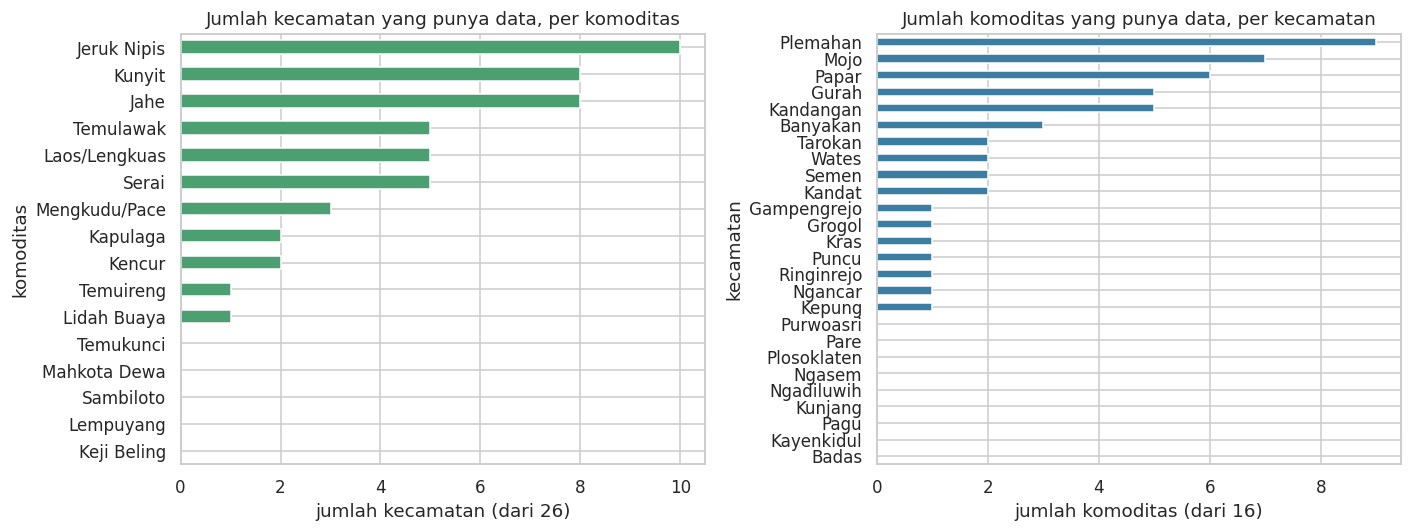

Komoditas TANPA data sama sekali : ['Keji Beling', 'Lempuyang', 'Sambiloto', 'Mahkota Dewa', 'Temukunci']
Kecamatan TANPA data sama sekali : ['Badas', 'Kayenkidul', 'Pagu', 'Kunjang', 'Ngadiluwih', 'Ngasem', 'Plosoklaten', 'Pare', 'Purwoasri']


In [ ]:
fig, ax = plt.subplots(1, 2, figsize=(13, 5))

per_kom = kec.groupby("komoditas")["ada_data"].sum().sort_values()
per_kom.plot.barh(ax=ax[0], color="#4c9f70")
ax[0].set_title("Jumlah kecamatan yang punya data, per komoditas")
ax[0].set_xlabel("jumlah kecamatan (dari 26)")

per_kec = kec.groupby("kecamatan")["ada_data"].sum().sort_values()
per_kec.plot.barh(ax=ax[1], color="#3b7ea1")
ax[1].set_title("Jumlah komoditas yang punya data, per kecamatan")
ax[1].set_xlabel("jumlah komoditas (dari 16)")

plt.tight_layout(); plt.show()

print("Komoditas TANPA data sama sekali :", per_kom[per_kom == 0].index.tolist())
print("Kecamatan TANPA data sama sekali :", per_kec[per_kec == 0].index.tolist())

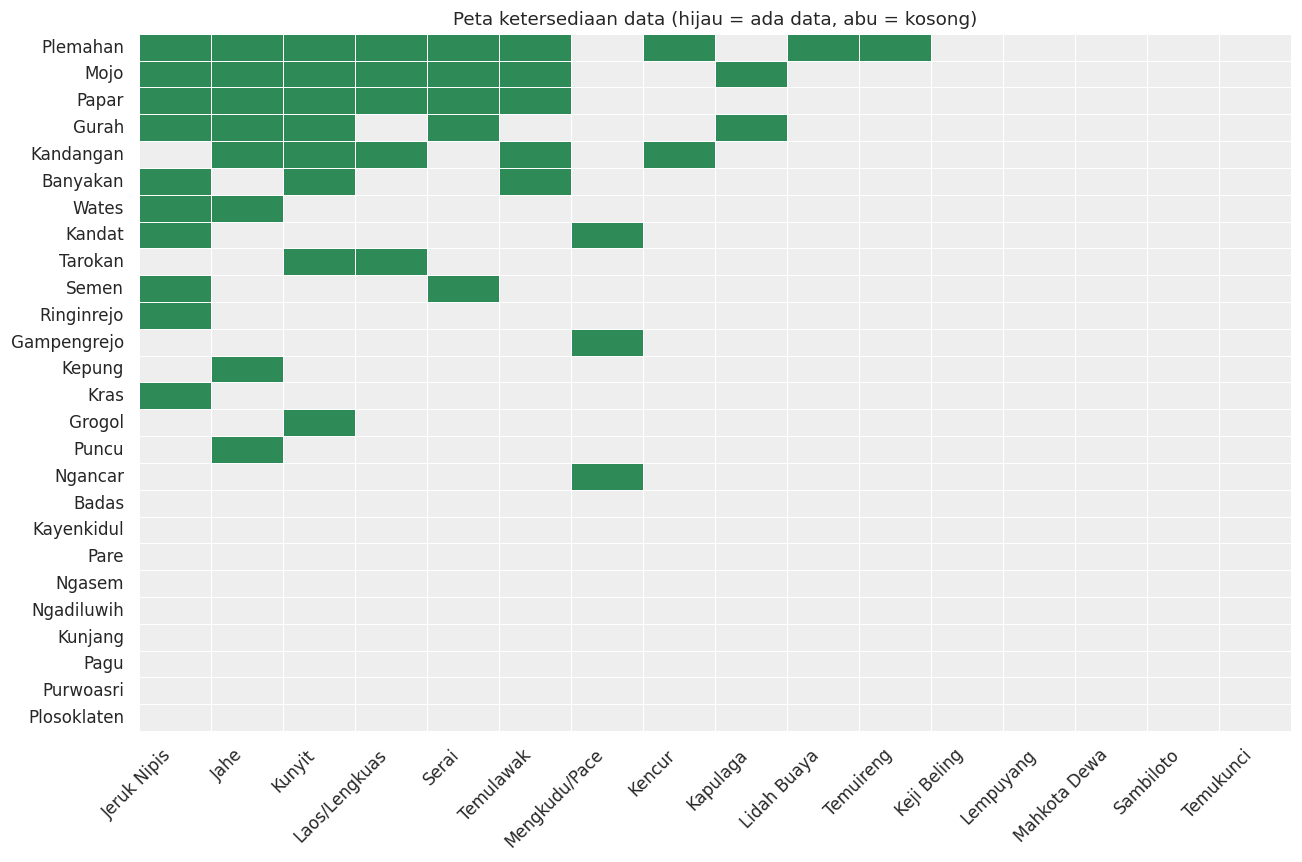

In [ ]:
pv = kec.pivot_table(index="kecamatan", columns="komoditas", values="ada_data", aggfunc="first").astype(int)
pv = pv.loc[pv.sum(axis=1).sort_values(ascending=False).index, pv.sum().sort_values(ascending=False).index]

plt.figure(figsize=(12, 8))
sns.heatmap(pv, cmap=["#eeeeee", "#2e8b57"], cbar=False, linewidths=.5, linecolor="white")
plt.title("Peta ketersediaan data (hijau = ada data, abu = kosong)")
plt.xlabel(""); plt.ylabel("")
plt.xticks(rotation=45, ha="right")
plt.tight_layout(); plt.show()

Data **sangat jarang (sparse)**: sebagian besar kombinasi kecamatan × komoditas kosong. Ini wajar karena tidak semua tanaman biofarmaka ditanam di semua kecamatan, tapi penting diingat sebelum membuat model atau kesimpulan.

### 4.2 Statistik deskriptif per komoditas

In [ ]:
stat = (kec_valid.groupby(["komoditas", "satuan"])
        .agg(n_kecamatan=("kecamatan", "nunique"),
             total_luas=("luas_panen", "sum"),
             median_luas=("luas_panen", "median"),
             total_produksi_kg=("produksi_kg", "sum"),
             median_produksi_kg=("produksi_kg", "median"),
             maks_produksi_kg=("produksi_kg", "max"))
        .sort_values("total_produksi_kg", ascending=False))
stat

,,n_kecamatan,total_luas,median_luas,total_produksi_kg,median_produksi_kg,maks_produksi_kg
komoditas,satuan,,,,,,
Kunyit,m2,8,"4,476,188.00","1,350.00","6,045,767.00","5,865.00","4,379,000.00"
Temulawak,m2,5,"804,499.00",400.00,"884,763.00","1,136.00","875,000.00"
Jeruk Nipis,Pohon,10,"18,823.00",275.00,"374,273.00","5,404.00","303,000.00"
Jahe,m2,8,"92,260.00","2,442.50","133,603.00","4,938.50","58,000.00"
Serai,Pohon,5,"8,366.00",211.00,"62,124.00",755.00,"40,500.00"
Kapulaga,m2,2,"5,505.00","2,752.50","21,263.00","10,631.50","21,250.00"
Lidah Buaya,m2,1,"1,650.00","1,650.00","12,595.00","12,595.00","12,595.00"
Laos/Lengkuas,m2,5,"3,504.00","1,000.00","11,444.00","1,200.00","7,000.00"
Mengkudu/Pace,Pohon,3,802.00,70.00,"6,972.00",458.00,"6,450.00"


### 4.3 Distribusi nilai

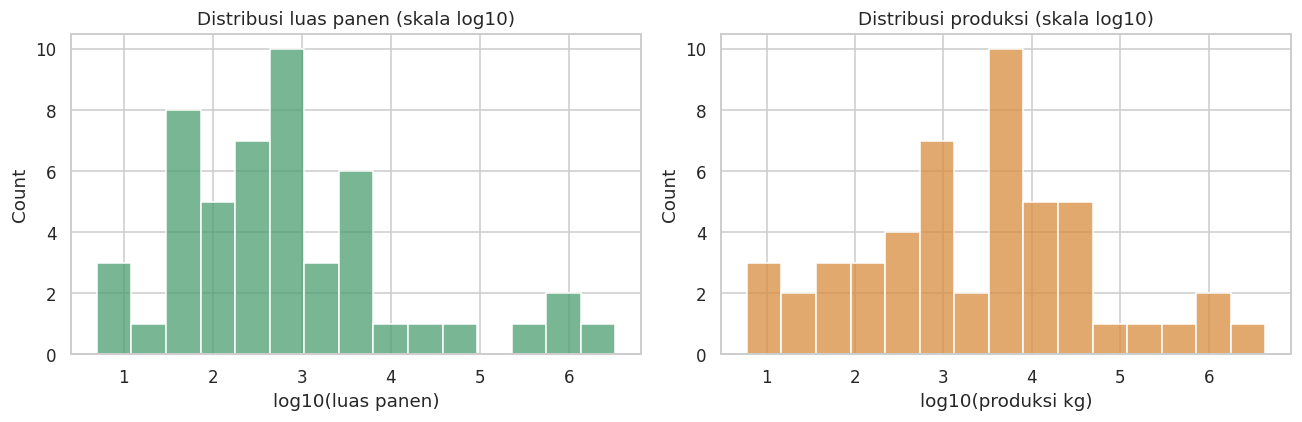

Skewness data asli  -> luas: 6.04 | produksi: 5.92
Skewness setelah log -> luas: 0.92 | produksi: 0.16


In [ ]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
sns.histplot(np.log10(kec_valid["luas_panen"]), bins=15, color="#4c9f70", ax=ax[0])
ax[0].set_title("Distribusi luas panen (skala log10)")
ax[0].set_xlabel("log10(luas panen)")
sns.histplot(np.log10(kec_valid["produksi_kg"]), bins=15, color="#d98c3f", ax=ax[1])
ax[1].set_title("Distribusi produksi (skala log10)")
ax[1].set_xlabel("log10(produksi kg)")
plt.tight_layout(); plt.show()

print("Skewness data asli  -> luas:", round(kec_valid["luas_panen"].skew(), 2),
      "| produksi:", round(kec_valid["produksi_kg"].skew(), 2))
print("Skewness setelah log -> luas:", round(np.log10(kec_valid["luas_panen"]).skew(), 2),
      "| produksi:", round(np.log10(kec_valid["produksi_kg"]).skew(), 2))

Data asli sangat miring ke kanan (beberapa nilai raksasa, banyak nilai kecil), jadi untuk visualisasi dipakai **skala log**.

### 4.4 Komoditas dominan (level kabupaten)

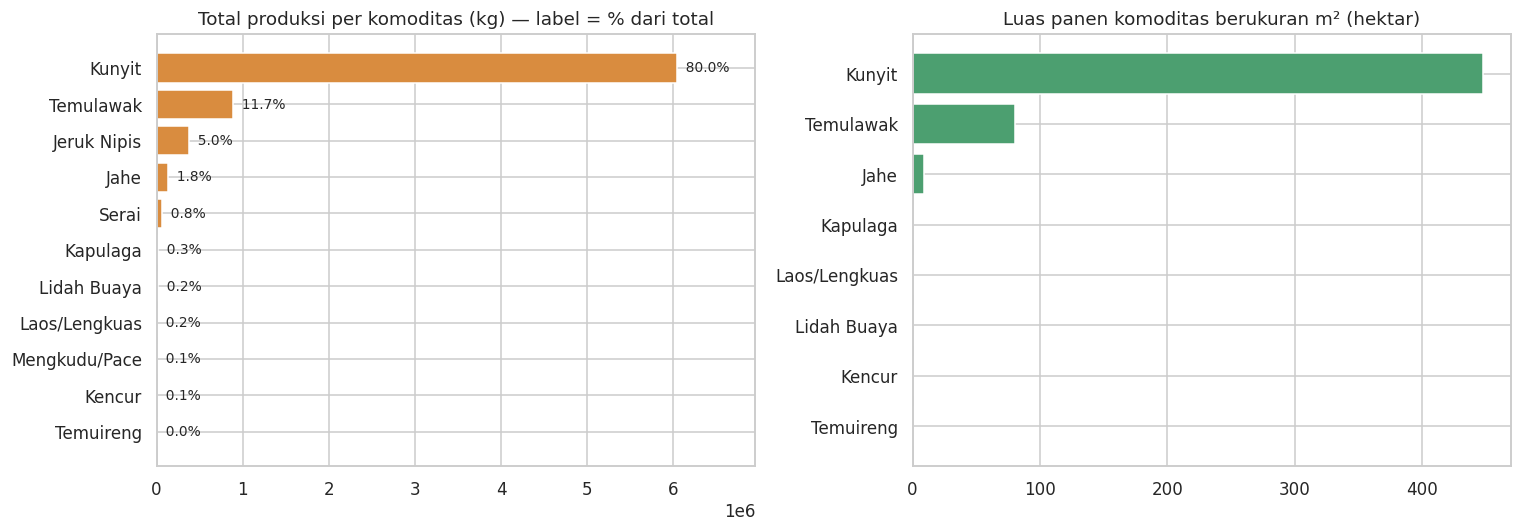

Kunyit + Temulawak = 91.7% dari total produksi


In [ ]:
k = kab_valid.sort_values("produksi_kg")
k["persen"] = k["produksi_kg"] / k["produksi_kg"].sum() * 100

fig, ax = plt.subplots(1, 2, figsize=(14, 5))
ax[0].barh(k["komoditas"], k["produksi_kg"], color="#d98c3f")
for y, (v, p) in enumerate(zip(k["produksi_kg"], k["persen"])):
    ax[0].text(v, y, f"  {p:.1f}%", va="center", fontsize=9)
ax[0].set_title("Total produksi per komoditas (kg) — label = % dari total")
ax[0].set_xlim(0, k["produksi_kg"].max() * 1.15)

m2 = kab_valid[kab_valid["satuan"] == "m2"].sort_values("luas_ha")
ax[1].barh(m2["komoditas"], m2["luas_ha"], color="#4c9f70")
ax[1].set_title("Luas panen komoditas berukuran m² (hektar)")
plt.tight_layout(); plt.show()

print(f"Kunyit + Temulawak = {k.set_index('komoditas').loc[['Kunyit','Temulawak'], 'persen'].sum():.1f}% dari total produksi")

### 4.5 Kecamatan penghasil terbesar

,total_produksi_kg,n_komoditas,persen,persen_kumulatif
kecamatan,,,,
Banyakan,"5,259,500.00",3,69.57,69.57
Grogol,"1,400,000.00",1,18.52,88.09
Semen,"323,000.00",2,4.27,92.36
Tarokan,"255,530.00",2,3.38,95.74
Mojo,"127,450.00",7,1.69,97.43
Puncu,"58,000.00",1,0.77,98.20
Kepung,"46,560.00",1,0.62,98.81
Kandangan,"32,476.00",5,0.43,99.24
Plemahan,"19,255.00",9,0.25,99.50


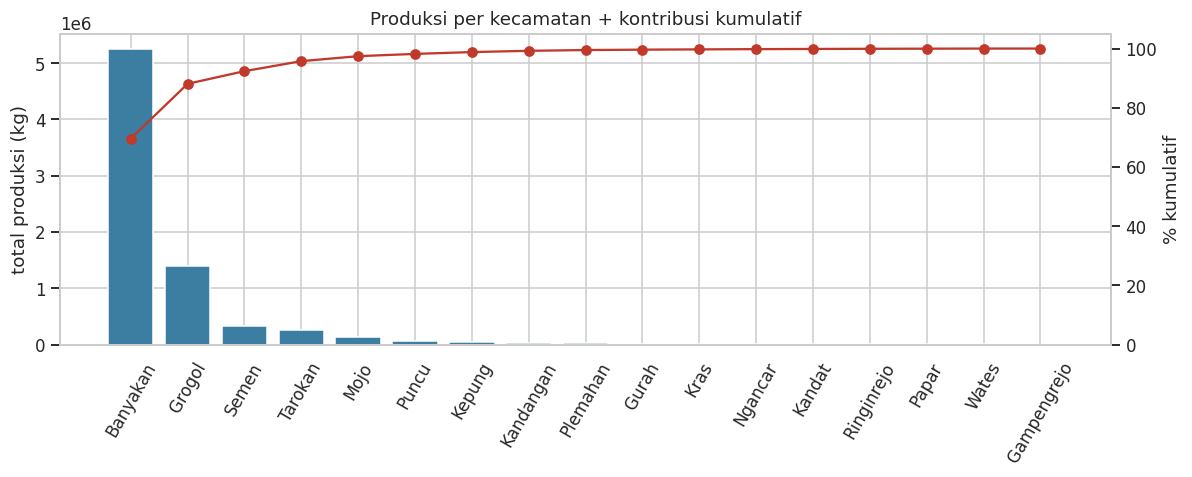

In [ ]:
kc = (kec_valid.groupby("kecamatan")
      .agg(total_produksi_kg=("produksi_kg", "sum"), n_komoditas=("komoditas", "nunique"))
      .sort_values("total_produksi_kg", ascending=False))
kc["persen"] = kc["total_produksi_kg"] / kc["total_produksi_kg"].sum() * 100
kc["persen_kumulatif"] = kc["persen"].cumsum()
display(kc)

fig, ax = plt.subplots(figsize=(11, 4.5))
ax.bar(kc.index, kc["total_produksi_kg"], color="#3b7ea1")
ax.set_ylabel("total produksi (kg)")
ax.tick_params(axis="x", rotation=60)
ax2 = ax.twinx()
ax2.plot(kc.index, kc["persen_kumulatif"], color="#c0392b", marker="o")
ax2.set_ylabel("% kumulatif"); ax2.set_ylim(0, 105); ax2.grid(False)
plt.title("Produksi per kecamatan + kontribusi kumulatif")
plt.tight_layout(); plt.show()

### 4.6 Heatmap produksi: kecamatan × komoditas

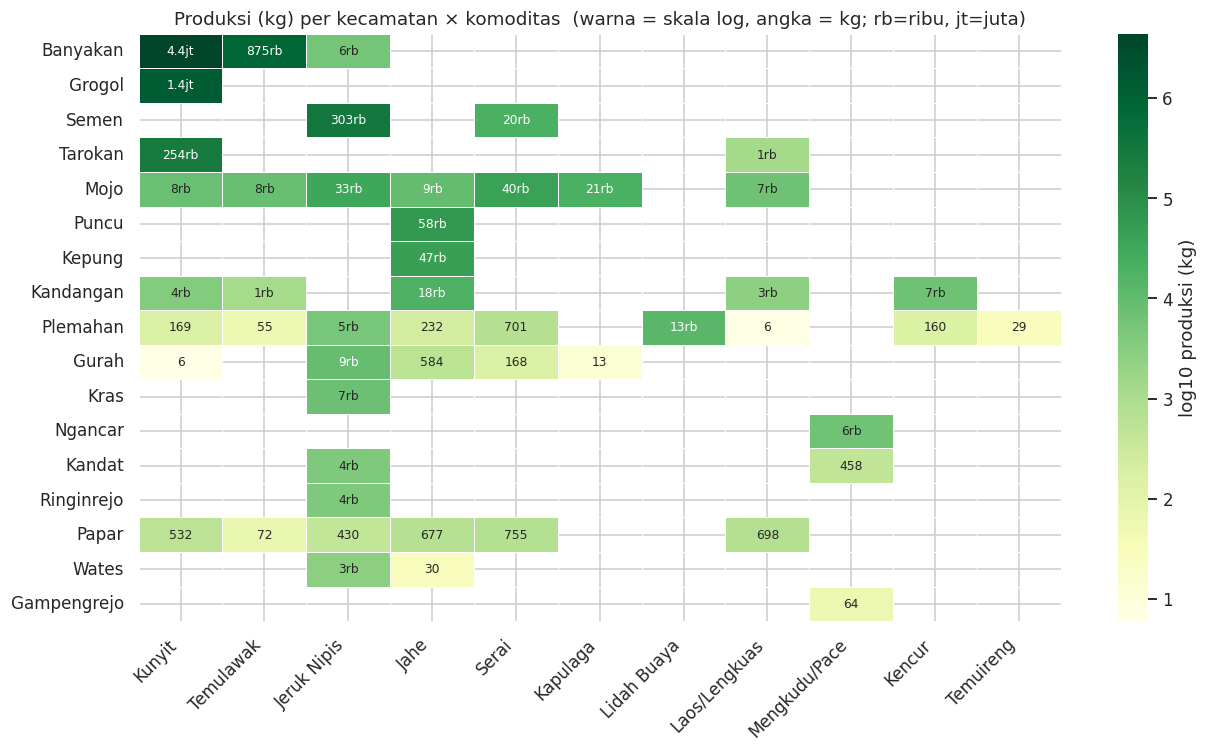

In [ ]:
def ringkas(x):
    if pd.isna(x): return ""
    if x >= 1e6: return f"{x/1e6:.1f}jt"
    if x >= 1e3: return f"{x/1e3:.0f}rb"
    return f"{x:.0f}"

pvt = kec_valid.pivot_table(index="kecamatan", columns="komoditas", values="produksi_kg", aggfunc="sum")
pvt = pvt.loc[pvt.sum(axis=1).sort_values(ascending=False).index, pvt.sum().sort_values(ascending=False).index]

plt.figure(figsize=(12, 7))
sns.heatmap(np.log10(pvt), annot=pvt.map(ringkas), fmt="", cmap="YlGn", linewidths=.5,
            linecolor="white", cbar_kws={"label": "log10 produksi (kg)"}, annot_kws={"size": 8})
plt.title("Produksi (kg) per kecamatan × komoditas  (warna = skala log, angka = kg; rb=ribu, jt=juta)")
plt.xlabel(""); plt.ylabel("")
plt.xticks(rotation=45, ha="right")
plt.tight_layout(); plt.show()

### 4.7 Hubungan luas panen vs produksi

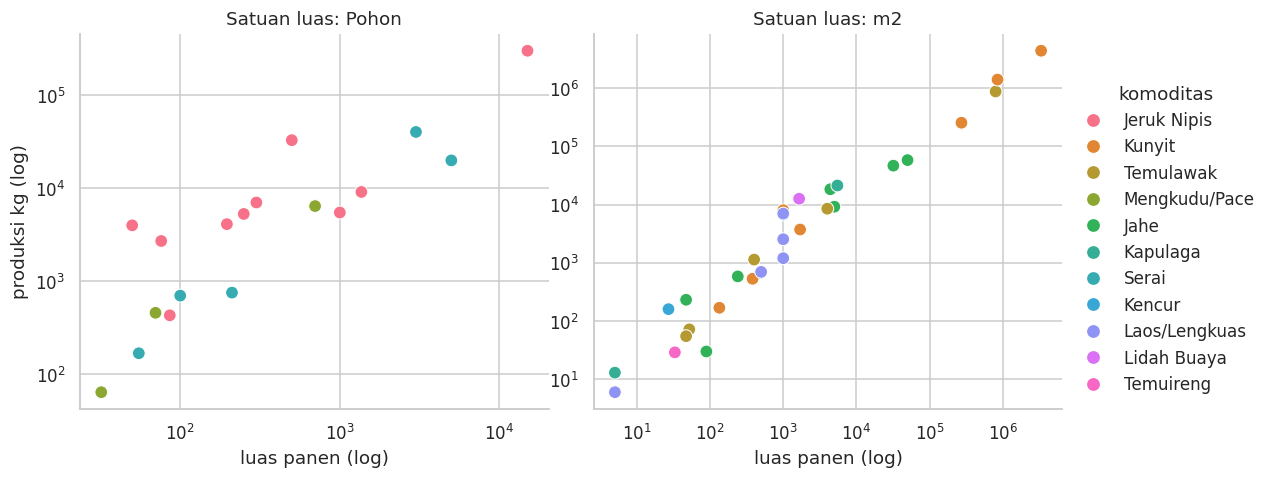

Korelasi Spearman luas vs produksi (Pohon, n=18): 0.897
Korelasi Spearman luas vs produksi (m2   , n=32): 0.980


In [ ]:
g = sns.relplot(data=kec_valid, x="luas_panen", y="produksi_kg", hue="komoditas", col="satuan",
                s=70, height=4.5, aspect=1.15, facet_kws={"sharex": False, "sharey": False})
for a in g.axes.flat:
    a.set_xscale("log"); a.set_yscale("log")
g.set_titles("Satuan luas: {col_name}")
g.set_axis_labels("luas panen (log)", "produksi kg (log)")
plt.show()

for s, d in kec_valid.groupby("satuan"):
    rho = d["luas_panen"].corr(d["produksi_kg"], method="spearman")
    print(f"Korelasi Spearman luas vs produksi ({s:5s}, n={len(d)}): {rho:.3f}")

Luas panen dan produksi hampir selalu naik bersama — masuk akal karena semakin luas lahan, semakin banyak hasilnya.

### 4.8 Produktivitas (hasil per satuan luas)

Dihitung terpisah: **kg/ha** untuk komoditas m², **kg/pohon** untuk komoditas pohon.

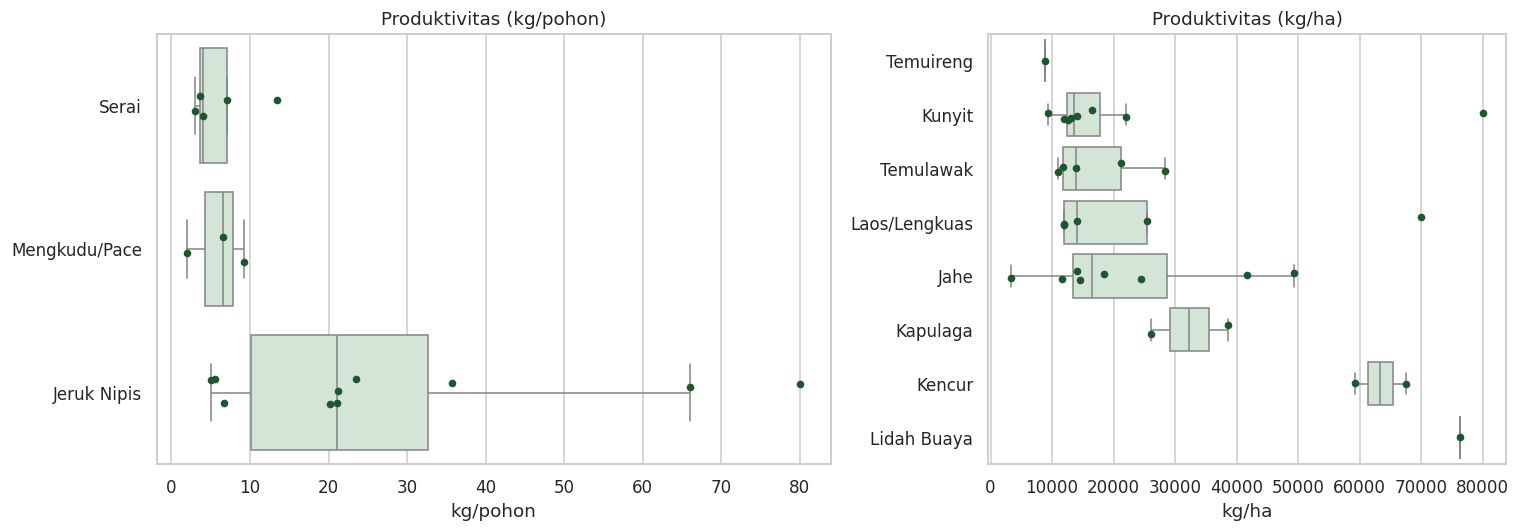

In [ ]:
fig, ax = plt.subplots(1, 2, figsize=(14, 5), gridspec_kw={"width_ratios": [1.3, 1]})
for a, (s, d) in zip(ax, kec_valid.groupby("satuan")):
    urut = d.groupby("komoditas")["produktivitas"].median().sort_values().index
    sns.boxplot(data=d, y="komoditas", x="produktivitas", order=urut, color="#cfe8d5", fliersize=0, ax=a)
    sns.stripplot(data=d, y="komoditas", x="produktivitas", order=urut, color="#1e5631", size=5, ax=a)
    a.set_title(f"Produktivitas ({d['satuan_produktivitas'].iloc[0]})")
    a.set_xlabel(d["satuan_produktivitas"].iloc[0]); a.set_ylabel("")
plt.tight_layout(); plt.show()

In [ ]:
# Tandai produktivitas yang jauh dari median komoditasnya (hanya komoditas dengan >= 3 kecamatan)
kec_valid["median_kom"] = kec_valid.groupby("komoditas")["produktivitas"].transform("median")
kec_valid["n_kom"] = kec_valid.groupby("komoditas")["produktivitas"].transform("count")
kec_valid["rasio_median"] = kec_valid["produktivitas"] / kec_valid["median_kom"]

curiga = kec_valid[(kec_valid["n_kom"] >= 3) & ((kec_valid["rasio_median"] > 2.5) | (kec_valid["rasio_median"] < 0.4))]
curiga[["kecamatan", "komoditas", "luas_panen", "produksi_kg", "produktivitas", "satuan_produktivitas", "rasio_median"]] \
    .sort_values("rasio_median", ascending=False)

,kecamatan,komoditas,luas_panen,produksi_kg,produktivitas,satuan_produktivitas,rasio_median
181,Mojo,Kunyit,"1,000.00","8,000.00","80,000.00",kg/ha,5.92
182,Mojo,Laos/Lengkuas,"1,000.00","7,000.00","70,000.00",kg/ha,5.00
97,Kandat,Jeruk Nipis,50.00,"4,000.00",80.00,kg/pohon,3.79
188,Mojo,Serai,"3,000.00","40,500.00",13.50,kg/pohon,3.38
177,Mojo,Jeruk Nipis,500.00,"33,000.00",66.00,kg/pohon,3.12
288,Plemahan,Jahe,47.00,232.00,"49,361.70",kg/ha,3.00
80,Kandangan,Jahe,"4,400.00","18,320.00","41,636.36",kg/ha,2.53
65,Gurah,Jeruk Nipis,"1,365.00","9,150.00",6.70,kg/pohon,0.32
42,Gampengrejo,Mengkudu/Pace,32.00,64.00,2.00,kg/pohon,0.31
17,Banyakan,Jeruk Nipis,"1,000.00","5,500.00",5.50,kg/pohon,0.26


Baris di atas adalah yang produktivitasnya **>2,5× atau <0,4×** median komoditasnya. Ini hanya **tanda untuk dicek**, bukan otomatis salah — dengan data sedikit (n kecil) dan kebun yang kecil (luas puluhan m²), variasi besar itu wajar. Tidak ada yang dihapus.

## 5. Kesimpulan

**Struktur data**
- 4 file saling konsisten: kombinasi (wilayah, komoditas) cocok 1:1 antara luas & produksi, dan **total kecamatan = angka kabupaten** (selisih 0).
- 26 kecamatan × 16 komoditas = 416 baris, tapi hanya **50 baris (12%)** yang punya data. Sisanya kosong dan sengaja **tidak diisi 0 / imputasi**.
- 5 komoditas tidak punya data sama sekali (Keji Beling, Lempuyang, Mahkota Dewa, Sambiloto, Temukunci) dan 9 kecamatan tidak punya data sama sekali.

**Isi data**
- Produksi sangat terkonsentrasi di komoditas: **Kunyit dan Temulawak** ≈ 92% dari total produksi kabupaten.
- Produksi juga terkonsentrasi di wilayah: **Banyakan (≈70%) dan Grogol (≈19%)** menyumbang sekitar 88% total produksi. Kecamatan yang datanya banyak jenis (mis. Plemahan, Mojo, Papar) justru volumenya kecil.
- Sebaran nilai sangat miring ke kanan → pakai skala log untuk visualisasi/pemodelan.
- Luas panen dan produksi berkorelasi kuat.

**Catatan untuk tahap berikutnya**
1. Jangan jumlahkan atau bandingkan luas **m²** dengan **pohon** — selalu pisahkan menurut kolom `satuan`.
2. Karena data jarang, pertimbangkan fokus ke komoditas dengan data cukup (mis. Jeruk Nipis, Jahe, Kunyit) atau gunakan level kabupaten.
3. Data cuma satu periode (tidak ada kolom tahun) → belum bisa analisis tren waktu.
4. Ada 12 baris dengan produktivitas ekstrem (4 di antaranya dari Mojo). Sebaiknya dikonfirmasi ke sumber sebelum dipakai untuk model.

## 6. Simpan Data Bersih

In [ ]:
kolom_final = ["kecamatan", "komoditas", "satuan", "luas_panen", "luas_ha", "produksi_kg",
               "produktivitas", "satuan_produktivitas", "status_qc", "ada_data"]

kec[kolom_final].to_csv(os.path.join(OUT_BIOFARMAKA, "biofarmaka_kecamatan_lengkap.csv"), index=False)
kec_valid[kolom_final].to_csv(os.path.join(OUT_BIOFARMAKA, "biofarmaka_kecamatan_valid.csv"), index=False)
kab[["kabupaten"] + kolom_final[1:]].to_csv(os.path.join(OUT_BIOFARMAKA, "biofarmaka_kabupaten.csv"), index=False)

print("Tersimpan di:", OUT_BIOFARMAKA)
for f in sorted(os.listdir(OUT_BIOFARMAKA)):
    if f.endswith(".csv"):
        print(" -", f, f"({len(pd.read_csv(os.path.join(OUT_BIOFARMAKA, f)))} baris)")

Tersimpan di: path/ke/project/data/clean/biofarmaka
 - biofarmaka_kabupaten.csv (16 baris)
 - biofarmaka_kecamatan_lengkap.csv (416 baris)
 - biofarmaka_kecamatan_valid.csv (50 baris)
